In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv("../data/assam_merged_flood_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (87720, 21)


,timestamp,station_id,station_name,district,river,latitude,longitude,water_level_m,danger_level_m,rainfall_mm,...,humidity_pct,wind_speed_kmh,wind_direction_deg,solar_radiation_wm2,pressure_hpa,satellite_rainfall_mm,rainfall_intensity_mmh,flood_occurred,flood_severity,flood_extent_km2
0,2023-01-01 00:00:00,ASM_GW01,Guwahati Waterfront (Kamrup Metro),Kamrup Metropolitan,Brahmaputra,26.1859,91.7477,48.60,49.68,0.0,...,60.6,6.0,201.5,50.0,1011.8,0.88,0.88,0,NaN,0.0
1,2023-01-01 01:00:00,ASM_GW01,Guwahati Waterfront (Kamrup Metro),Kamrup Metropolitan,Brahmaputra,26.1859,91.7477,48.60,49.68,0.0,...,64.4,11.3,155.2,61.9,1012.0,1.03,1.03,0,NaN,0.0
2,2023-01-01 02:00:00,ASM_GW01,Guwahati Waterfront (Kamrup Metro),Kamrup Metropolitan,Brahmaputra,26.1859,91.7477,48.52,49.68,0.0,...,62.5,4.8,196.1,96.9,1013.3,0.00,0.00,0,NaN,0.0
3,2023-01-01 03:00:00,ASM_GW01,Guwahati Waterfront (Kamrup Metro),Kamrup Metropolitan,Brahmaputra,26.1859,91.7477,48.51,49.68,0.0,...,63.9,7.6,220.0,152.5,1012.0,2.30,2.30,0,NaN,0.0
4,2023-01-01 04:00:00,ASM_GW01,Guwahati Waterfront (Kamrup Metro),Kamrup Metropolitan,Brahmaputra,26.1859,91.7477,48.49,49.68,0.0,...,67.0,4.2,128.1,225.0,1011.6,1.33,1.33,0,NaN,0.0


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87720 entries, 0 to 87719
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               87720 non-null  str    
 1   station_id              87720 non-null  str    
 2   station_name            87720 non-null  str    
 3   district                87720 non-null  str    
 4   river                   87720 non-null  str    
 5   latitude                87720 non-null  float64
 6   longitude               87720 non-null  float64
 7   water_level_m           87720 non-null  float64
 8   danger_level_m          87720 non-null  float64
 9   rainfall_mm             87720 non-null  float64
 10  temperature_c           87720 non-null  float64
 11  humidity_pct            87720 non-null  float64
 12  wind_speed_kmh          87720 non-null  float64
 13  wind_direction_deg      87720 non-null  float64
 14  solar_radiation_wm2     87720 non-null  float64
 

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,87720.0,26.397280,0.885224,24.8333,26.1859,26.6338,26.8606,27.4728
longitude,87720.0,93.294340,1.133281,91.7477,92.7789,92.7926,94.2405,94.9120
water_level_m,87720.0,65.060950,29.465908,18.1400,48.5600,64.2600,85.7125,113.4100
danger_level_m,87720.0,65.196000,29.507027,19.8300,49.6800,65.2300,85.5400,105.7000
rainfall_mm,87720.0,2.552684,10.097616,0.0000,0.0000,0.0000,0.0000,189.4900
temperature_c,87720.0,21.612897,5.606007,12.0000,16.5000,21.6000,26.6000,35.2000
humidity_pct,87720.0,72.514121,11.191138,52.1000,64.6000,67.9000,79.1000,99.0000
wind_speed_kmh,87720.0,6.755212,3.083871,4.0000,4.6000,5.6000,7.5000,30.8000
wind_direction_deg,87720.0,179.810058,43.685497,23.2000,148.0000,179.8000,211.7000,352.3000
solar_radiation_wm2,87720.0,360.111622,248.962011,50.0000,125.5000,309.4000,575.0000,750.0000


In [24]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated(subset=["station_id", "timestamp"]).sum())

timestamp                     0
station_id                    0
station_name                  0
district                      0
river                         0
latitude                      0
longitude                     0
water_level_m                 0
danger_level_m                0
rainfall_mm                   0
temperature_c                 0
humidity_pct                  0
wind_speed_kmh                0
wind_direction_deg            0
solar_radiation_wm2           0
pressure_hpa                  0
satellite_rainfall_mm         0
rainfall_intensity_mmh        0
flood_occurred                0
flood_severity            63748
flood_extent_km2              0
dtype: int64
Duplicate rows: 0


In [25]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.drop_duplicates(subset=["station_id", "timestamp"])
df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

df["flood_severity"] = df["flood_severity"].fillna("None")
print(df["flood_severity"].value_counts())

flood_severity
None        63748
Critical    17474
Severe       2856
Moderate     2256
Low          1386
Name: count, dtype: int64


In [26]:
print("Dono columns same?", (df["rainfall_intensity_mmh"] == df["satellite_rainfall_mm"]).all())
df = df.drop(columns=["rainfall_intensity_mmh"])

Dono columns same? True


In [27]:
df["rainfall_mm"] = df["rainfall_mm"].clip(lower=0).fillna(0)
df["satellite_rainfall_mm"] = df["satellite_rainfall_mm"].clip(lower=0).fillna(0)
df["humidity_pct"] = df["humidity_pct"].clip(0, 100)

weather_cols = ["water_level_m", "temperature_c", "humidity_pct", "wind_speed_kmh",
                "wind_direction_deg", "solar_radiation_wm2", "pressure_hpa"]

df[weather_cols] = df.groupby("station_id")[weather_cols].transform(
    lambda x: x.interpolate(method="linear", limit_direction="both"))
df[weather_cols] = df.groupby("station_id")[weather_cols].transform(
    lambda x: x.fillna(x.median()))

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


In [28]:
for stn, data in df.groupby("station_id"):
    print(stn, dict(data["timestamp"].diff().value_counts()))

ASM_DB02 {Timedelta('0 days 01:00:00'): np.int64(17543)}
ASM_GW01 {Timedelta('0 days 01:00:00'): np.int64(17543)}
ASM_JR05 {Timedelta('0 days 01:00:00'): np.int64(17543)}
ASM_SL03 {Timedelta('0 days 01:00:00'): np.int64(17543)}
ASM_TZ04 {Timedelta('0 days 01:00:00'): np.int64(17543)}


rainfall_mm            outliers =  12756 | flood in these =  66.4%
satellite_rainfall_mm  outliers =   9466 | flood in these =  75.0%
temperature_c          outliers =      0 | flood in these =   0.0%
humidity_pct           outliers =      0 | flood in these =   0.0%
wind_speed_kmh         outliers =   9916 | flood in these =  71.0%
solar_radiation_wm2    outliers =      0 | flood in these =   0.0%
pressure_hpa           outliers =   2407 | flood in these =  99.3%


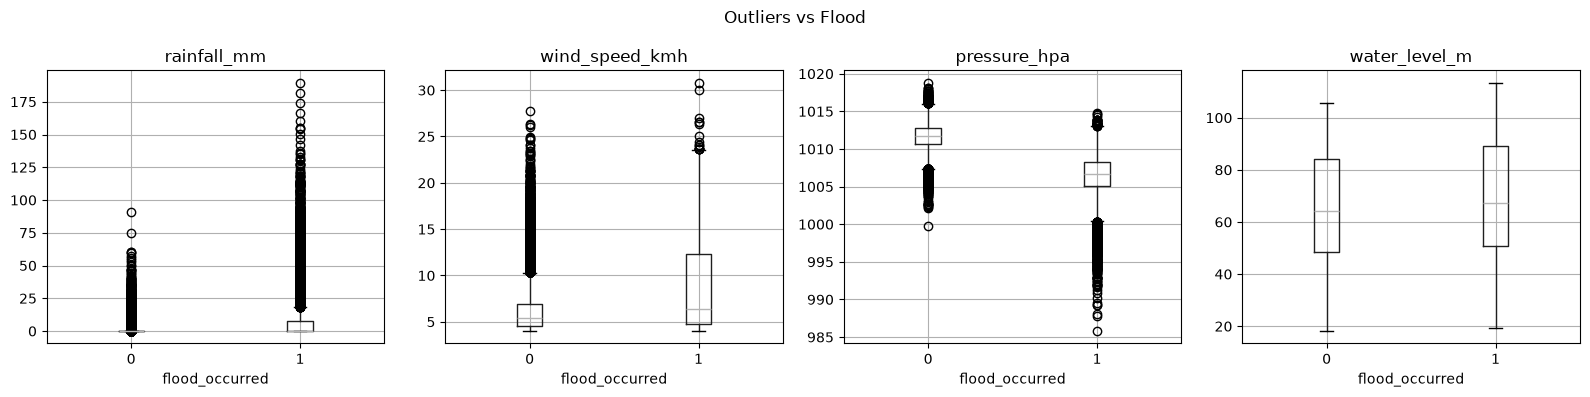

In [29]:
iqr_cols = ["rainfall_mm", "satellite_rainfall_mm", "temperature_c", "humidity_pct",
            "wind_speed_kmh", "solar_radiation_wm2", "pressure_hpa"]

for col in iqr_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = (df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)
    flood_pct = df.loc[outliers, "flood_occurred"].mean() * 100 if outliers.sum() > 0 else 0
    print(f"{col:22s} outliers = {outliers.sum():6d} | flood in these = {flood_pct:5.1f}%")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["rainfall_mm", "wind_speed_kmh", "pressure_hpa", "water_level_m"]):
    df.boxplot(column=col, by="flood_occurred", ax=ax)
    ax.set_title(col)
plt.suptitle("Outliers vs Flood")
plt.tight_layout()
plt.show()

In [30]:
print(pd.crosstab(df["water_level_m"] >= df["danger_level_m"], df["flood_occurred"]))

flood_occurred      0      1
row_0                       
False           63748     12
True                0  23960


In [31]:
df.to_csv("../data/flood_clean.csv", index=False)
print("Saved! Shape:", df.shape)

Saved! Shape: (87720, 20)


In [32]:
import pandas as pd

df = pd.read_csv("../data/assam_real_flood_dataset.csv", parse_dates=["timestamp"], low_memory=False)
df["year"] = df["timestamp"].dt.year
df = df.sort_values(["station_id", "timestamp"])

# 1) floods per station per year: hours above DANGER level and number of separate floods
df["above_danger"] = (df["water_level_m"] >= df["danger_level_m"]).astype(int)
df["above_warning"] = (df["water_level_m"] >= df["danger_level_m"] - 1).astype(int)   # CWC warning = danger - 1 m
for col in ["above_danger", "above_warning"]:
    df[col + "_start"] = (df.groupby("station_id")[col].diff() == 1).astype(int)

table = df.groupby(["station_name", "year"]).agg(
    danger_hours=("above_danger", "sum"), danger_floods=("above_danger_start", "sum"),
    warning_hours=("above_warning", "sum"), warning_floods=("above_warning_start", "sum"),
    min_level=("water_level_m", "min"), max_level=("water_level_m", "max"))
print(table.round(2).to_string())

# 2) very low readings (possible CWC errors)
for name, g in df.groupby("station_name"):
    low = g["water_level_m"].quantile(0.001)
    print(f"\n{name}: 0.1% lowest level = {low:.2f} m | min = {g['water_level_m'].min():.2f} m on "
          f"{g.loc[g['water_level_m'].idxmin(), 'timestamp']}")

                                         danger_hours  danger_floods  warning_hours  warning_floods  min_level  max_level
station_name                       year                                                                                  
Dibrugarh Ghat                     2023            38              1            964               3     102.24     105.87
                                   2024            25              1           1391              10     101.86     105.80
                                   2025            18              1           1555              22     101.56     105.85
                                   2026             0              0           2433               5     101.62     105.49
Guwahati Waterfront (Kamrup Metro) 2023             2              2            453               3      29.70      49.68
                                   2024             4              3            372               5      29.69      49.68
                        